In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, shock_analysis, plot_predictive_density_ax, plot_bimodality_and_series_2
from MLE_Predictive_Density import neg_loglik_student_mar, neg_loglik_student_marx, mar_studentt_pred_density, marx_studentt_pred_density


In [2]:
# Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol


### Import WTI and detrend series with HP filter + linear trend of the volatility scaling

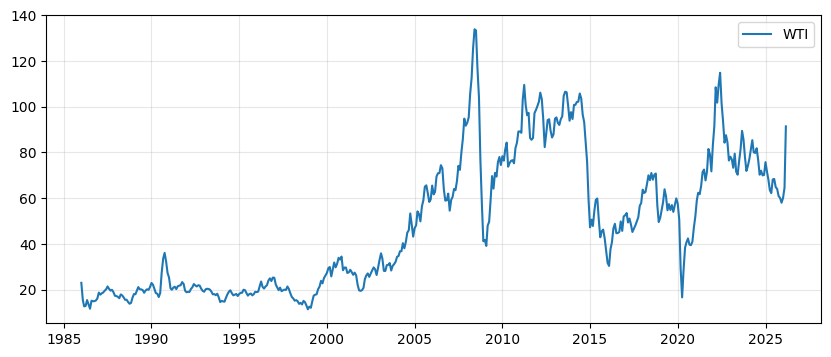

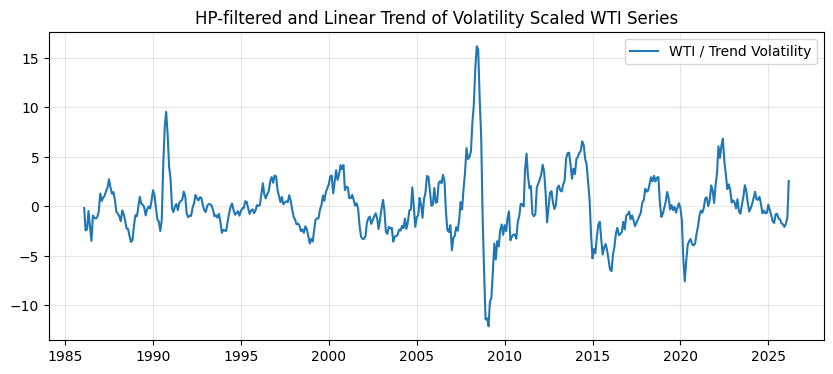

In [3]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter
cycle, trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

df_wti["wti_cycle"] = cycle
df_wti["wti_trend"] = trend

# Compute differences and linear trend volatility estimation
wti_diff = (df_wti["wti_cycle"]).diff()
wti_vol = linear_vol_scale(wti_diff)

df_wti["wti_scaled_cycle"] = df_wti["wti_cycle"]/wti_vol


# -------------------------
# PLOTS
# -------------------------

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_wti.index, df_wti["MCOILWTICO"], label="WTI")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(df_wti["wti_scaled_cycle"], label="WTI / Trend Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.title("HP-filtered and Linear Trend of Volatility Scaled WTI Series")
plt.show()

### Extract and Transform Data for Exogeous Variables

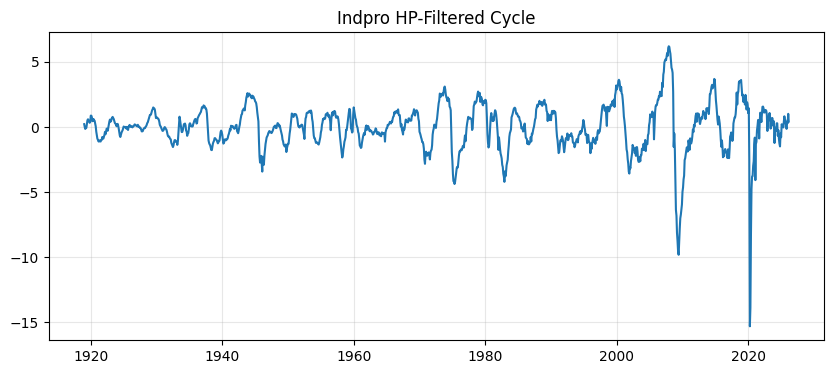

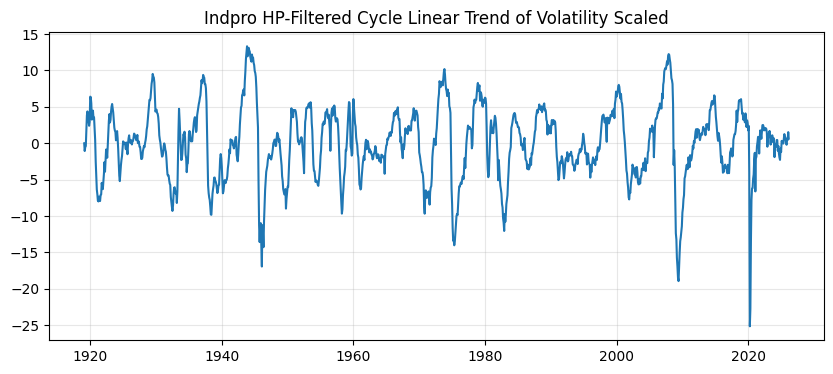

In [4]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma = linear_vol_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

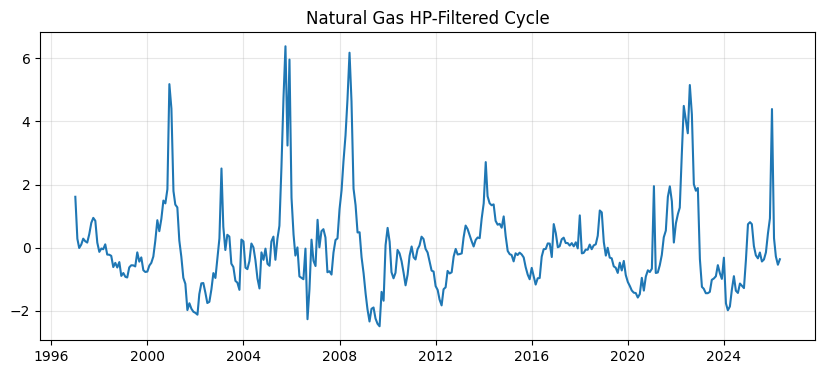

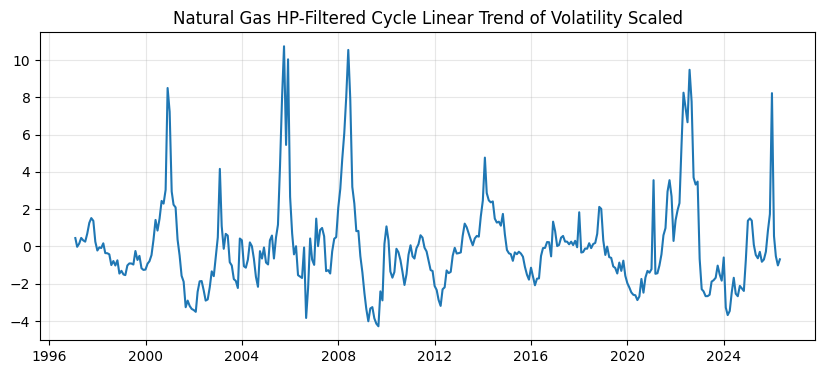

In [5]:
# -------------------------
# Natural Gas
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
ngas_cycle, ngas_trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

ngas_diff = (ngas_cycle).diff().dropna()
ngas_sigma = linear_vol_scale(ngas_diff)

ngas= ngas_cycle/ngas_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_cycle)
plt.title("Natural Gas HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas)
plt.title("Natural Gas HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

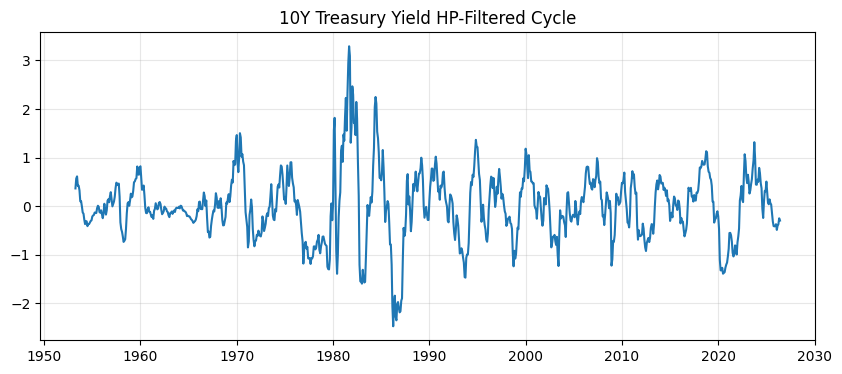

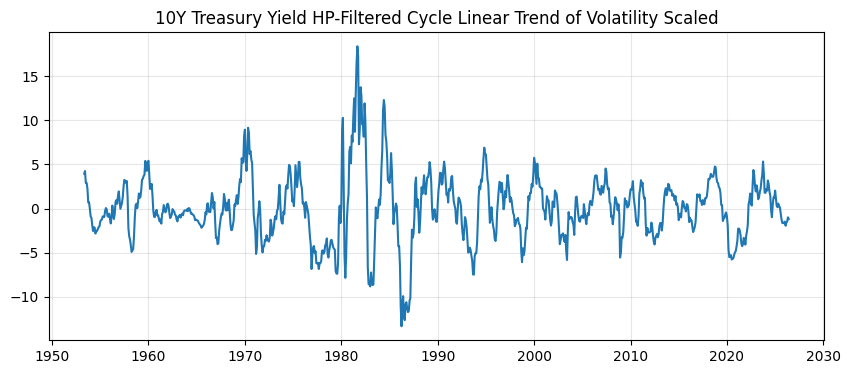

In [6]:
# -------------------------
# 10 Year Treasury Yield
# -------------------------
df_10y_treasury = pd.read_csv("GS10.csv", parse_dates=["observation_date"])
df_10y_treasury = df_10y_treasury.dropna().set_index("observation_date")


# HP filter + linear trend of the volatility scaling
treasury_10y_cycle , trend = hpfilter(df_10y_treasury["GS10"], lamb=129600)

treasury_10y_diff = (treasury_10y_cycle).diff().dropna()
treasury_10y_sigma = linear_vol_scale(treasury_10y_diff)

treasury_10y= treasury_10y_cycle/treasury_10y_sigma


plt.figure(figsize=(10,4))
plt.plot(treasury_10y_cycle)
plt.title("10Y Treasury Yield HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(treasury_10y)
plt.title("10Y Treasury Yield HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_17501/3103116893.py:4: DtypeWarning: Columns (2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,495,496,497,498,499,500,501,502,503,504,505,506,507,508,509,510,511,512,513,514,515,516,517,518,519,520,521,522,523,524,525,526,527,528,529,530,531,532,533,534,535,536,537,538,539,540,541,542,543,544,545,546,547,548,549,550,551,552,553,554,555,556,557,558,559,560,561,562,563,564,565,566,567,568,569,570,571,572,573,574,575,576,577,578,579,580,581,582,583,584,585,586,587,588,589,590,591,592,593,594,595,596,597,598,599,600,601,602,603,604,605,606,607,608,609,610,611,612,613,614,615,616,617,618,619,620,621,622,623) have mixed types. Specify dtype op

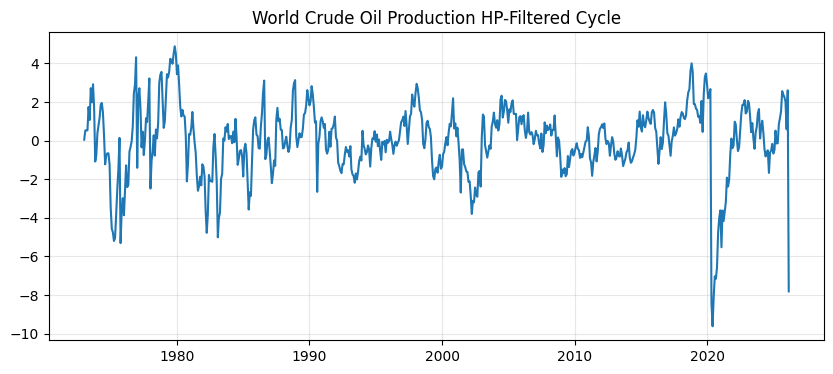

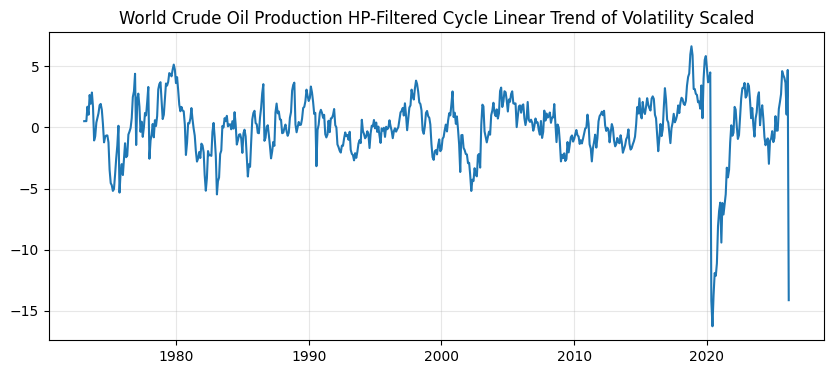

In [7]:
# -------------------------
# World Crude Oil Production
# -------------------------
df_oil = pd.read_csv(
    "World Crude Oil Production.csv",
    skiprows=1
)

# Select the World crude oil production row
world_crude = df_oil[
    df_oil["API"].str.contains("WORL", na=False) &
    df_oil.iloc[:,1].str.contains("Crude oil including lease condensate", na=False)
]


# Keep only the monthly data (drop metadata columns)
oil_series = world_crude.iloc[0, 2:]

# Convert the column names (YYYYMM) to dates
oil_series.index = pd.to_datetime(oil_series.index, format="%b %Y")

# Convert values to numeric
oil_series = pd.to_numeric(oil_series, errors="coerce").dropna()

# HP filter + linear trend of the volatility scaling

oil_series=0.001*oil_series
world_oil_cycle, oil_trend = hpfilter(oil_series, lamb=129600)

world_oil_diff = (world_oil_cycle).diff().dropna()
world_oil_sigma = linear_vol_scale(world_oil_diff)

world_oil= world_oil_cycle/world_oil_sigma


plt.figure(figsize=(10,4))
plt.plot(world_oil_cycle)
plt.title("World Crude Oil Production HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(world_oil)
plt.title("World Crude Oil Production HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

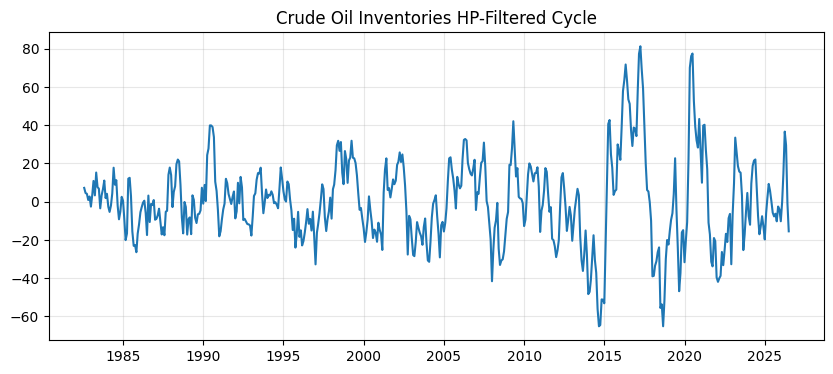

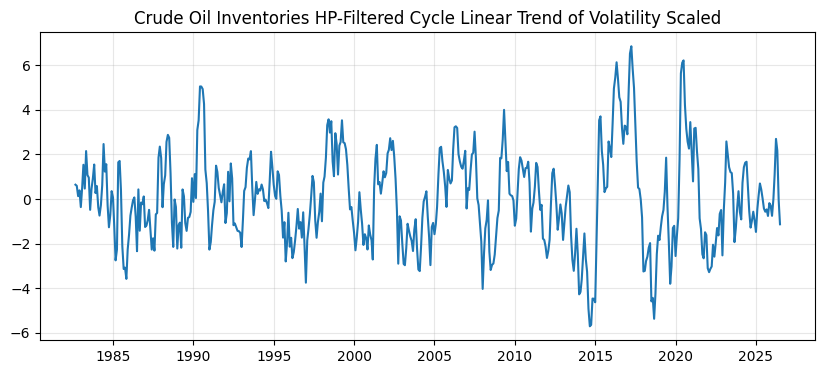

In [8]:
# -------------------------
# Crude Oil Inventories
# -------------------------

df_inv = pd.read_excel(
    "Crude Oil Inventories WEEKLY.xls",
    sheet_name="Data 1",      
    skiprows=2                
)

# Convert dates
df_inv["Date"] = pd.to_datetime(df_inv["Date"])

# Keep the first weekly observation of each month
df_inv = (
    df_inv.sort_values("Date")
          .groupby(df_inv["Date"].dt.to_period("M"), as_index=False)
          .first()
)

# Set dates to the first day of each month
df_inv["Date"] = df_inv["Date"].dt.to_period("M").dt.to_timestamp()

# Set index
df_inv = df_inv.set_index("Date").dropna()

# -------------------------
# HP Filter + linear trend of the volatility scaling
# -------------------------
df_inv=0.001*df_inv
crudeoil_inventory_cycle, crudeoil_inventory_trend = hpfilter(
    df_inv["Weekly U.S. Ending Stocks excluding SPR of Crude Oil  (Thousand Barrels)"],  
    lamb=129600
)

crudeoil_inventory_diff = (crudeoil_inventory_cycle).diff().dropna()
crudeoil_inventory_sigma = linear_vol_scale(crudeoil_inventory_diff)

crudeoil_inventory= crudeoil_inventory_cycle/crudeoil_inventory_sigma


plt.figure(figsize=(10,4))
plt.plot(crudeoil_inventory_cycle)
plt.title("Crude Oil Inventories HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(crudeoil_inventory)
plt.title("Crude Oil Inventories HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Data and Parameters 
df = pd.concat(
    [
        df_wti["wti_scaled_cycle"], indpro, ngas, treasury_10y, world_oil, crudeoil_inventory
    ],
    axis=1
).dropna()

df.columns = ["wti_scaled_cycle","indpro", "ngas", "treasury_10y", "world_oil", "crudeoil_inventory"]
df = df.sort_index()

start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["wti_scaled_cycle"].values
X = df[[ "indpro", "ngas", "treasury_10y", "world_oil",  "crudeoil_inventory"]].values

var = ["indpro", "ngas", "treasury_10y", "world_oil", "crudeoil_inventory"]



print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

t1=len(y)-1 # point to calculate predictive density


#Define Grid for all experiments
grid_min=-100
grid_max=100
ngrid=2000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)

#Parameters for effect of exogenous regressors on bimodality 
std=10
values=30

prominence = 0.01
y_limits=(-20, 20)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


In [10]:
# Get PSY data

import pickle

with open("psy_wti.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -540.079010840099

Estimated parameters:
phi             =     0.8389 (0.0346)
psi             =     0.3204 (0.0596)
sigma           =     0.8781 (0.0611)
nu              =     3.9976 (0.9280)

Hessian condition number:
1276.810907971113

Eigenvalues of Hessian:
[1.47947349e+03 5.11270482e+02 2.48022737e+02 1.15872561e+00]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -540.079011
AIC:            1088.158022
BIC:            1103.566832
R^2:            0.873775

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 3.403922, p-value = 0.0650416
    lag  5: statistic = 9.778980, p-value = 0.0817455
    lag 10: statistic = 16.917283, p-value = 0.0762145
    lag 20: statistic = 26.161018, p-value = 0.16056

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic

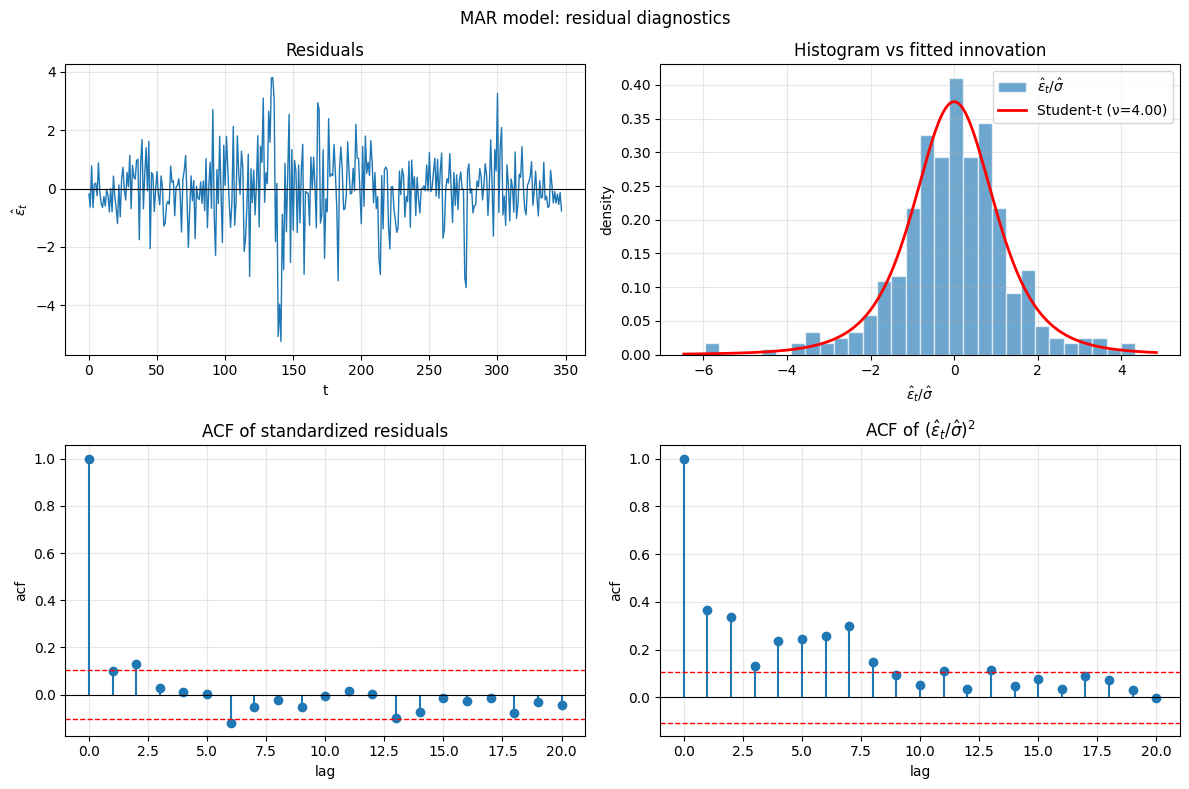

In [11]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

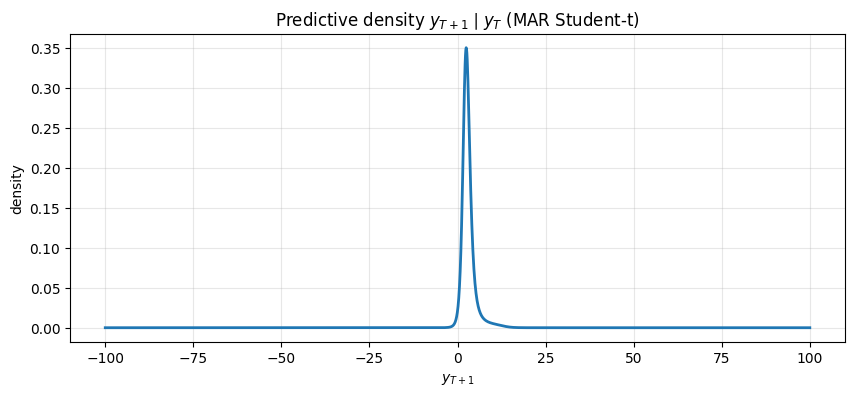

In [12]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

### Bimodality

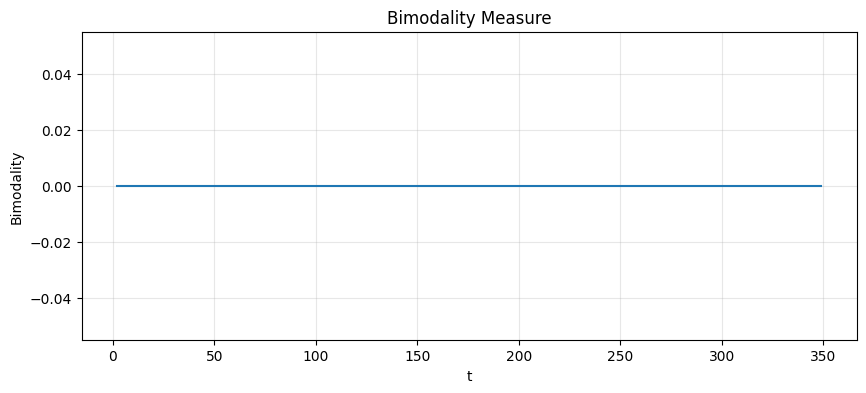

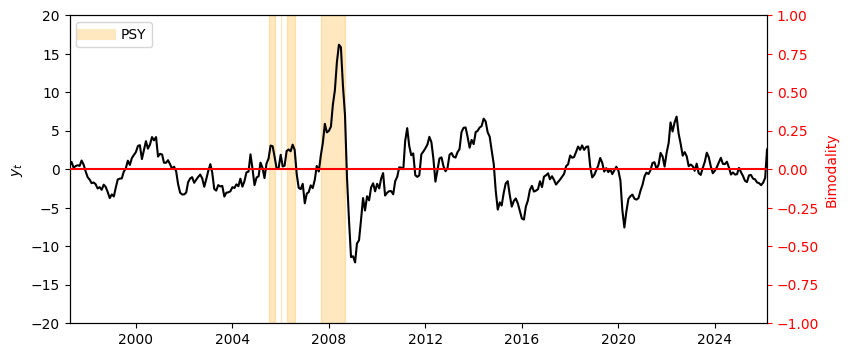

In [13]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


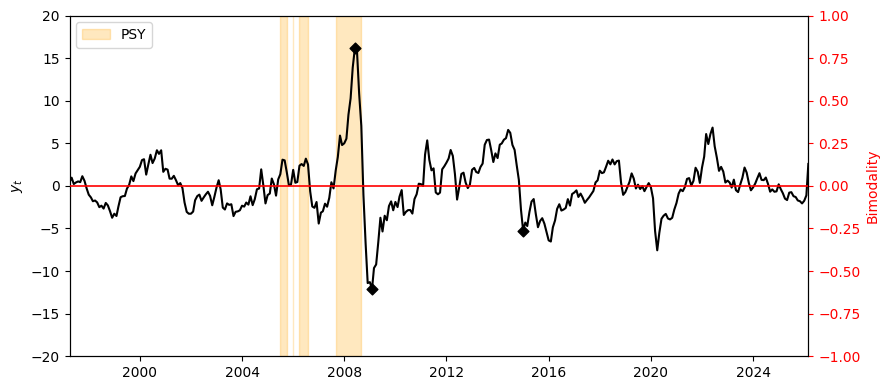

In [14]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[134, 142, 213]
)

### Predictive Density at selected points

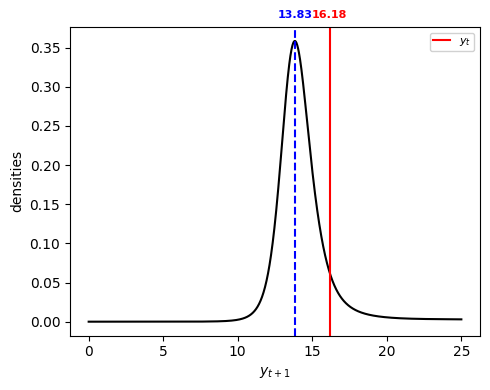

In [15]:
t0 = 136

grid1 = np.linspace(0, 25, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

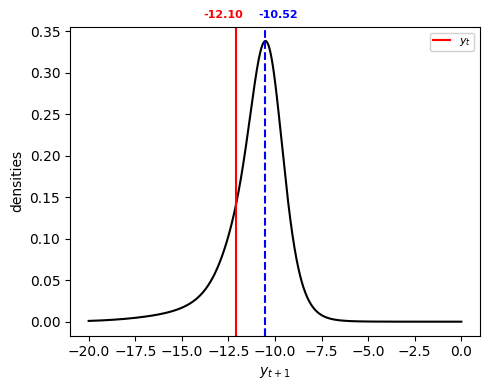

In [16]:
t0 = 144

grid1 = np.linspace(-20, 0, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

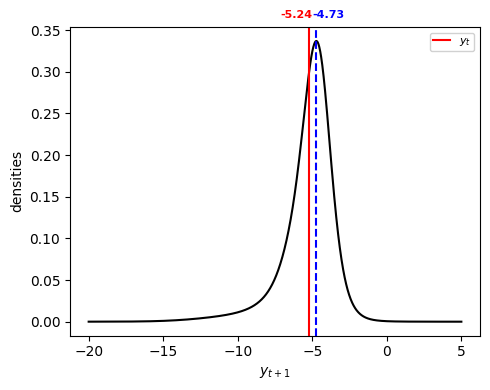

In [17]:
t0 = 215

grid1 = np.linspace(-20, 5, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -506.99951922435855

Estimated parameters:
phi             =     0.3841 (0.0539)
psi             =     0.6392 (0.0405)
beta_indpro     =     0.0549 (0.0147)
beta_ngas_cycle =     0.0983 (0.0275)
beta_treasury_10y =     0.0972 (0.0243)
beta_world_oil_cycle =    -0.0782 (0.0211)
beta_crudeoil_inventory =    -0.1124 (0.0261)
sigma           =     0.8248 (0.0563)
nu              =     4.5379 (1.1616)

Hessian condition number:
15441.14812940293

Eigenvalues of Hessian:
[1.14302012e+04 2.91434754e+03 2.14102037e+03 1.79519083e+03
 2.74334174e+02 7.40242962e-01 8.04764976e+02 6.11054266e+02
 1.17594118e+03]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -506.999519
AIC:            1031.999038
BIC:            1066.668861
R^2:            0.896988

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 1.967343, p-value = 0.16073
    lag  5: statistic =

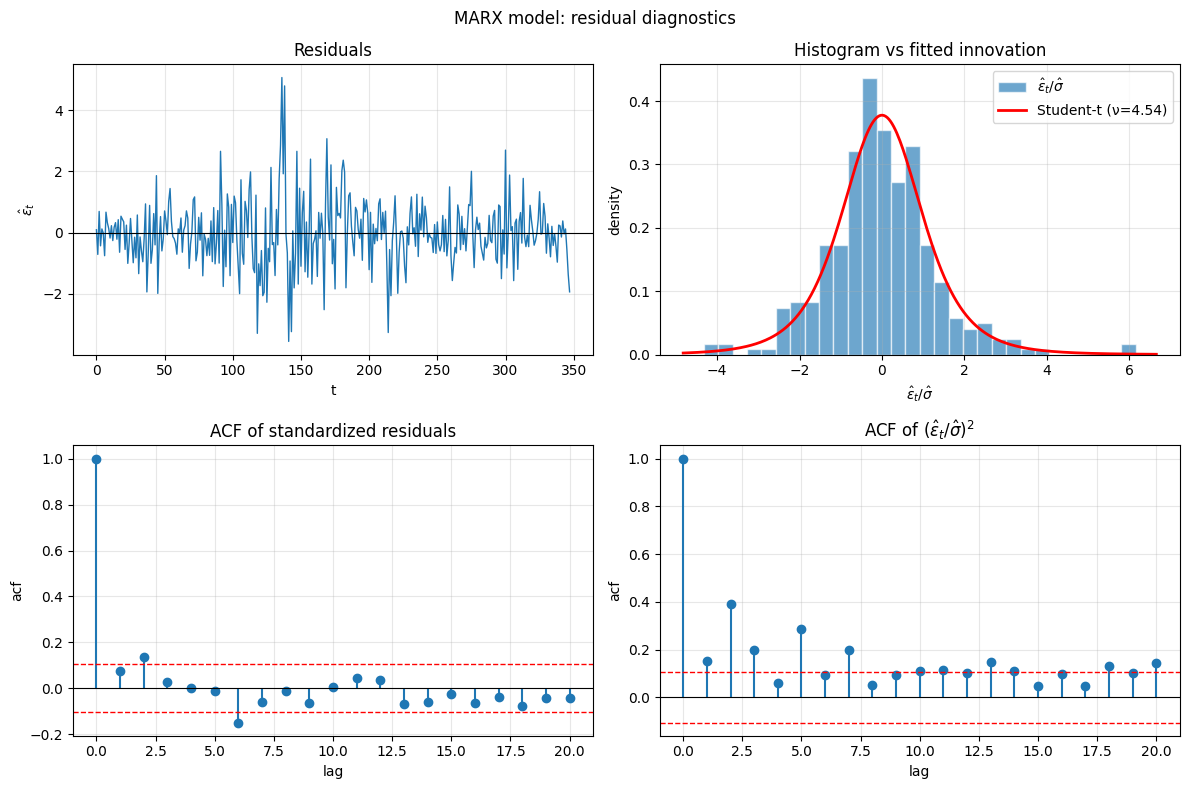

In [18]:
param_names = [ "phi", "psi", "beta_indpro", "beta_ngas_cycle", "beta_treasury_10y","beta_world_oil_cycle", "beta_crudeoil_inventory", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (0.1, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

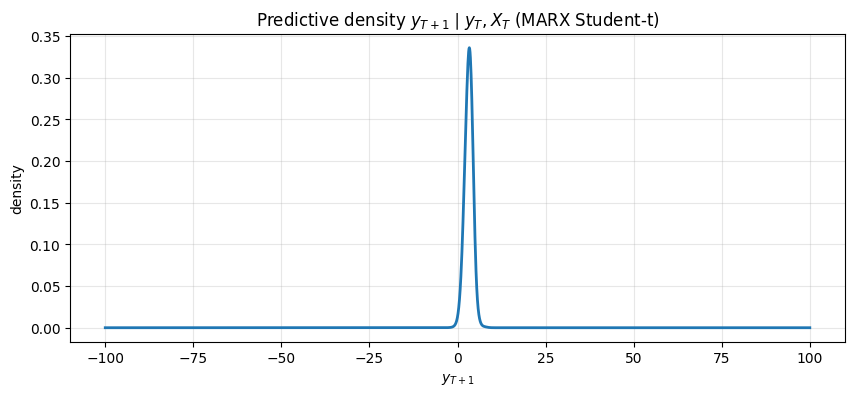

In [19]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

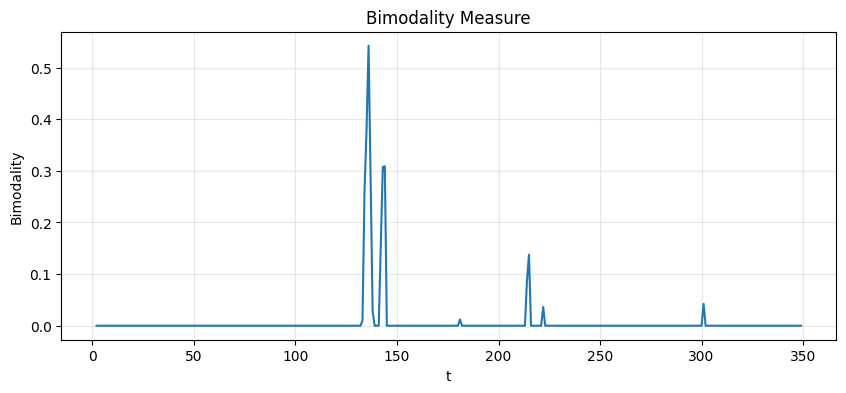

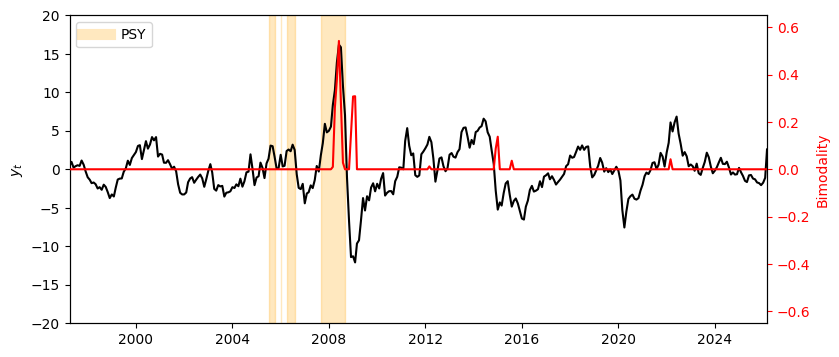

In [20]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


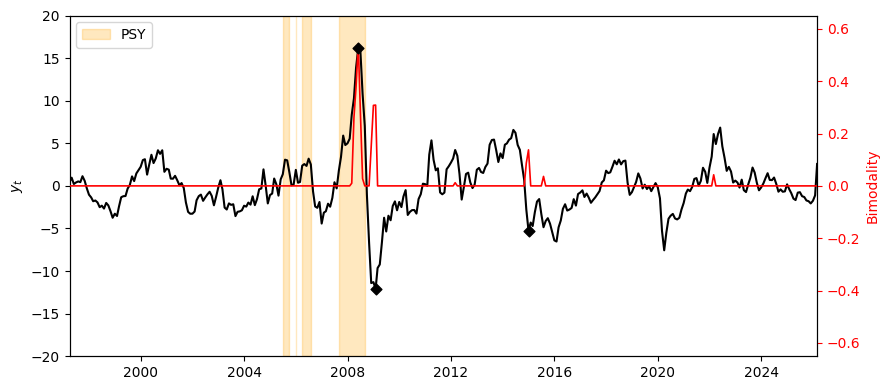

In [21]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[134, 142, 213]
)

### Predictive Density at selected points

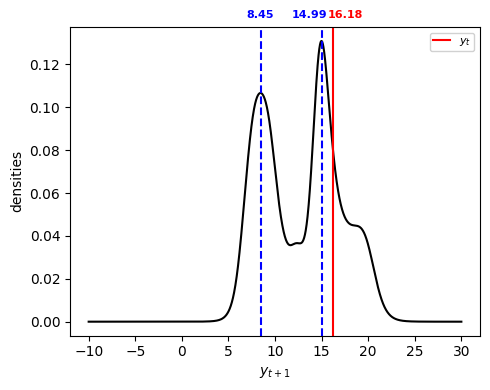

In [22]:
t0 = 136

grid1 = np.linspace(-10, 30, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

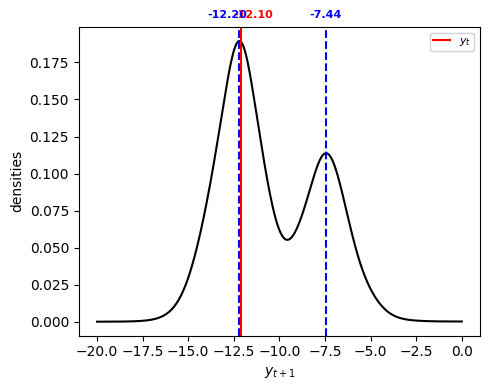

In [23]:
t0 = 144

grid1 = np.linspace(-20, 0, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

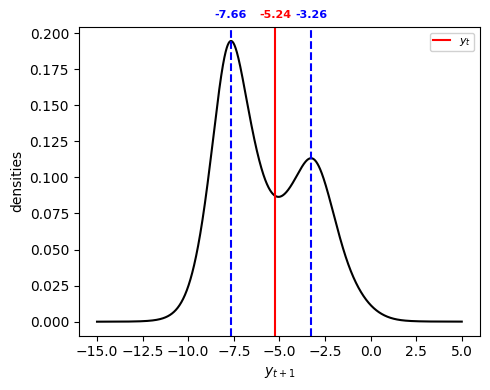

In [24]:
t0 = 215

grid1 = np.linspace(-15, 5, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

### Bimodality/ Predictive Density changes for different X values

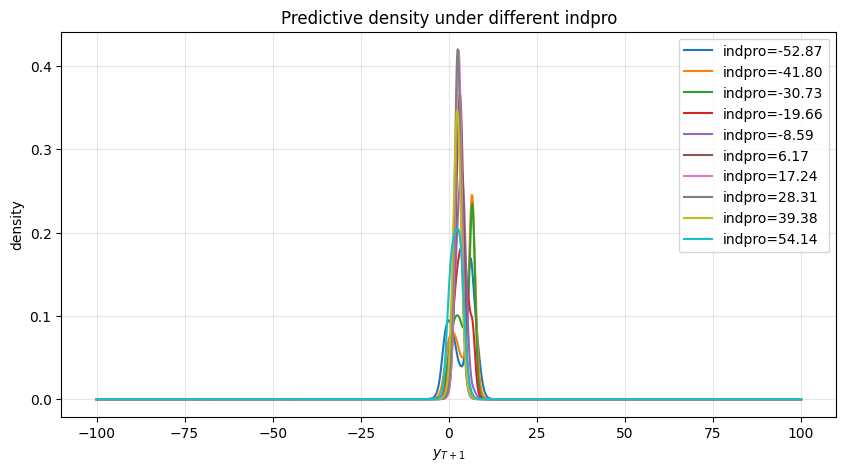

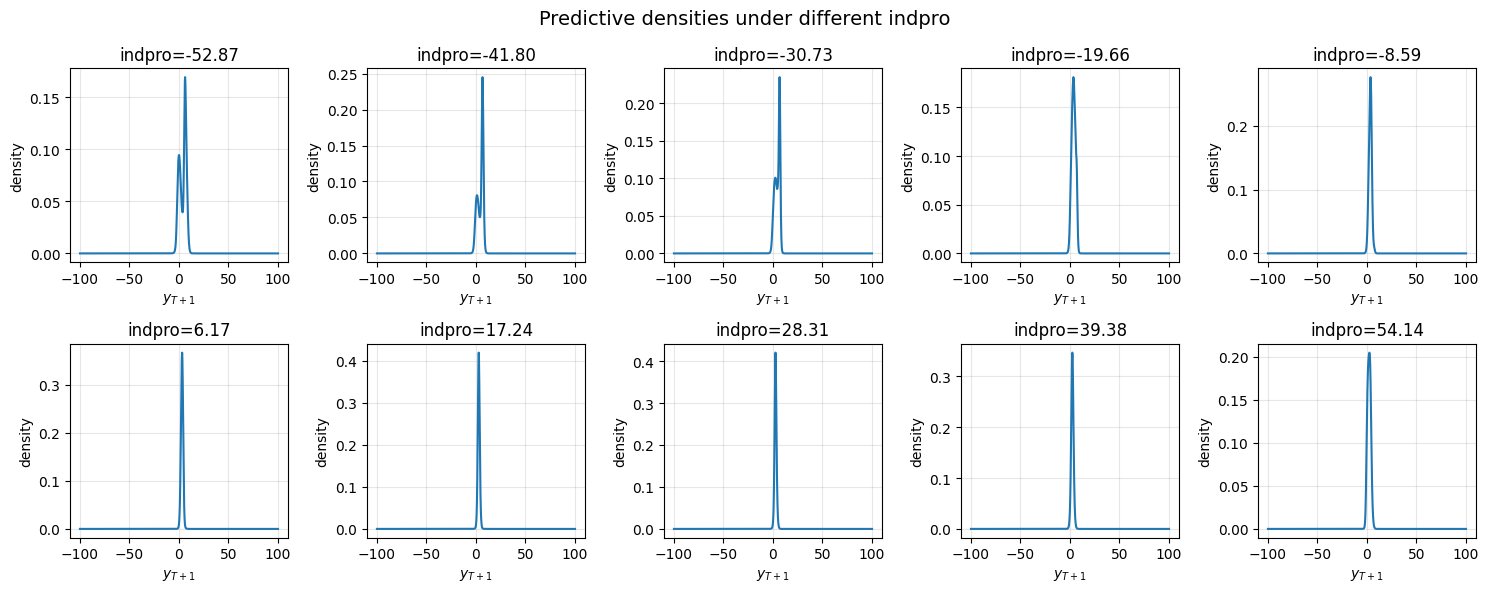

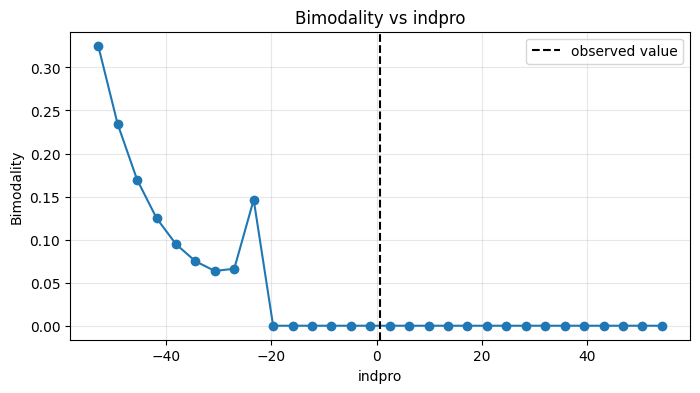

In [25]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t1,
    prominence_factor=prominence
)
